# 🪙 BitPredict AI — Bitcoin LSTM Price Prediction
## Dataset: BITCOIN Historical Datasets 2018–2026 (Binance API)
### 📌 Kaggle: https://www.kaggle.com/datasets/novandraanugrah/bitcoin-historical-datasets-2018-2024
---
**Model:** 3-Layer LSTM (100→100→50) | **Lookback:** 60 hari | **Split:** 80/20

**Cara pakai:**
1. Download dataset dari link Kaggle di atas → pilih file `BTC_1D_data_2018_to_2025.csv`
2. Letakkan di folder yang sama dengan notebook ini
3. Jalankan semua cell dari atas ke bawah
4. Step 9 akan mencetak output → copy paste ke `script.js`

In [1]:
# ══════════════════════════════════════════════════════════
# STEP 1 — Install & Import Libraries
# pip install tensorflow scikit-learn pandas numpy matplotlib yfinance
# ══════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import json, warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

DARK   = '#0d0e12'
SURF   = '#13151e'
GOLD   = '#F0B90B'
TEAL   = '#4ecdc4'
RED    = '#ff6b6b'
MUTED  = '#8b90ab'
print('✅ Libraries ready!')

✅ Libraries ready!


In [2]:
# ══════════════════════════════════════════════════════════
# STEP 2 — Load Dataset dari Kaggle
#
# 📥 Download dari:
#    https://www.kaggle.com/datasets/novandraanugrah/bitcoin-historical-datasets-2018-2024
#    → Pilih file: BTC_1D_data_2018_to_2025.csv
#
# Atau gunakan file BTC_USD_Binance_2018_2026.csv yang sudah disertakan
# ══════════════════════════════════════════════════════════

# ─── Option A: File dari Kaggle (BTC_1D_data_2018_to_2025.csv) ───
CSV_FILE = 'BTC_1D_data_2018_to_2025.csv'   # ← ganti nama file jika perlu

# ─── Option B: File yang sudah disertakan ───
# CSV_FILE = 'BTC_USD_Binance_2018_2026.csv'

# ─── Option C: Download live dari yfinance ───
# import yfinance as yf
# raw = yf.download('BTC-USD', start='2018-01-01', end='2026-03-26', progress=False)
# raw.reset_index(inplace=True)
# raw.rename(columns={'Price':'Date','Close':'Close'}, inplace=True)
# raw.to_csv('BTC_live.csv', index=False)
# CSV_FILE = 'BTC_live.csv'

df = pd.read_csv(CSV_FILE)

# Standardize column names (Kaggle dataset uses different casing)
df.columns = [c.strip().lower().replace(' ','_') for c in df.columns]
date_col  = [c for c in df.columns if 'date' in c or 'time' in c][0]
close_col = [c for c in df.columns if 'close' in c][0]

df = df[[date_col, close_col]].copy()
df.columns = ['Date', 'Close']
df['Date']  = pd.to_datetime(df['Date'])
df['Close'] = pd.to_numeric(df['Close'], errors='coerce')
df.dropna(inplace=True)
df.sort_values('Date', inplace=True)
df.reset_index(drop=True, inplace=True)

print(f'✅ Loaded  : {len(df):,} rows')
print(f'📅 Range   : {df.Date.min().date()} → {df.Date.max().date()}')
print(f'💰 Min     : ${df.Close.min():>12,.2f}')
print(f'💰 Max     : ${df.Close.max():>12,.2f}')
print(f'💰 Latest  : ${df.Close.iloc[-1]:>12,.2f}')
df.tail()

✅ Loaded  : 2,997 rows
📅 Range   : 2018-01-01 → 2026-03-16
💰 Min     : $    3,211.72
💰 Max     : $  125,046.94
💰 Latest  : $   72,750.01


,Date,Close
2992,2026-03-12 00:00:00+00:00,69894.00
2993,2026-03-13 00:00:00+00:00,71590.01
2994,2026-03-14 00:00:00+00:00,70880.82
2995,2026-03-15 00:00:00+00:00,71250.68
2996,2026-03-16 00:00:00+00:00,72750.01


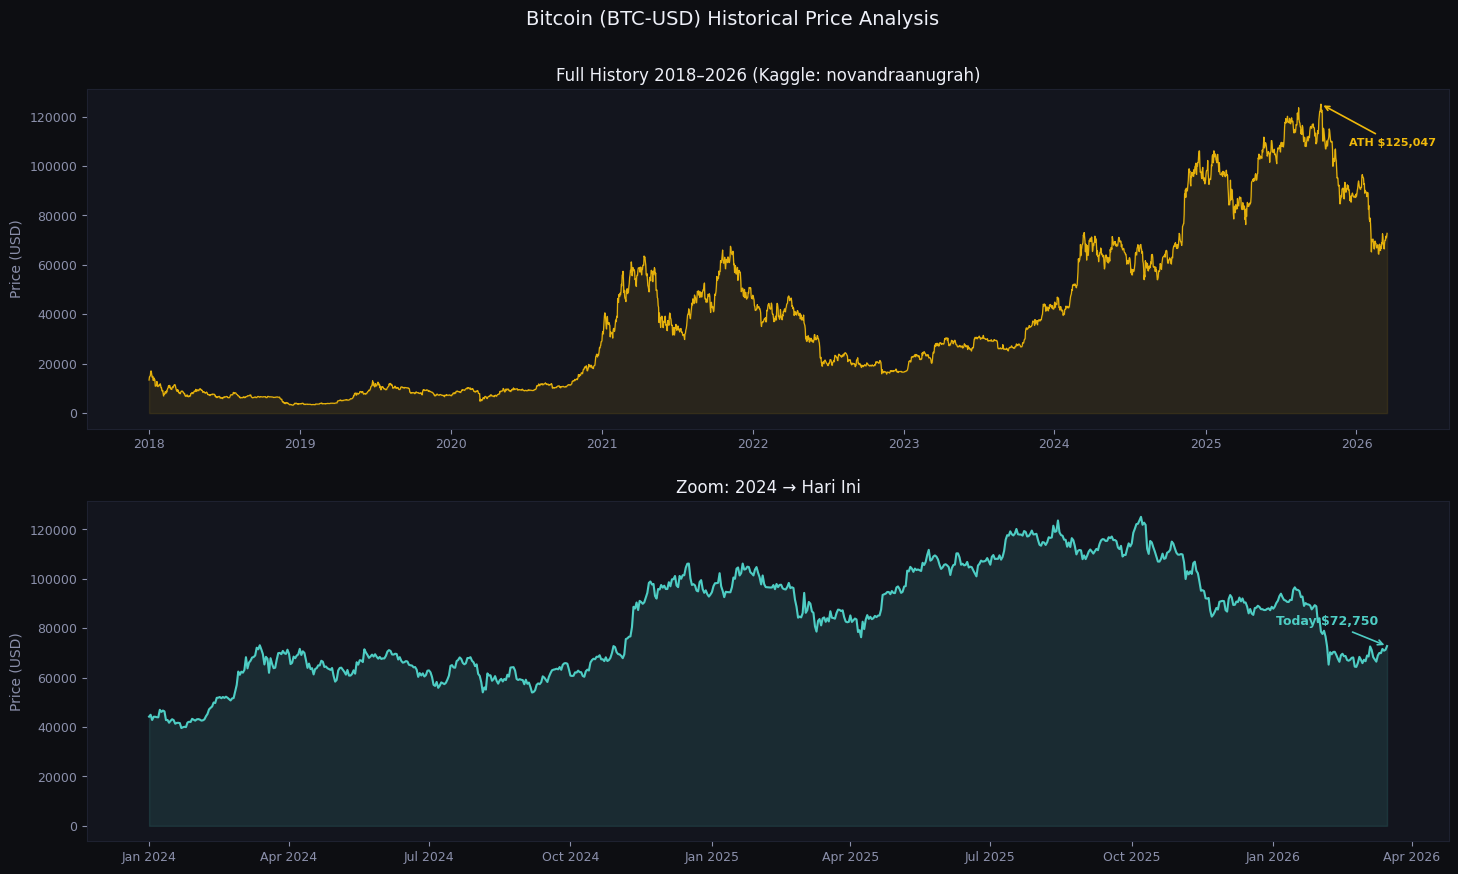

✅ Plot saved → btc_eda.png


In [3]:
# ══════════════════════════════════════════════════════════
# STEP 3 — EDA: Visualisasi Harga Bitcoin
# ══════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 1, figsize=(15, 9))
fig.patch.set_facecolor(DARK)
fig.suptitle('Bitcoin (BTC-USD) Historical Price Analysis', color='#eef0f8', fontsize=14, y=0.98)

for ax in axes:
    ax.set_facecolor(SURF)
    ax.tick_params(colors=MUTED, labelsize=9)
    for sp in ax.spines.values(): sp.set_color('#1e2130')

# Full history
axes[0].plot(df['Date'], df['Close'], color=GOLD, lw=.9, alpha=.95)
axes[0].fill_between(df['Date'], df['Close'], alpha=.10, color=GOLD)
axes[0].set_title('Full History 2018–2026 (Kaggle: novandraanugrah)', color='#eef0f8', fontsize=12)
axes[0].set_ylabel('Price (USD)', color=MUTED)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# ATH annotation
ath_i = df['Close'].idxmax()
axes[0].annotate(f"ATH ${df.Close[ath_i]:,.0f}",
    xy=(df.Date[ath_i], df.Close[ath_i]),
    xytext=(20,-30), textcoords='offset points',
    color=GOLD, fontsize=8, fontweight='bold',
    arrowprops=dict(arrowstyle='->', color=GOLD, lw=1.2))

# Zoom 2024–2026
recent = df[df.Date >= '2024-01-01']
axes[1].plot(recent['Date'], recent['Close'], color=TEAL, lw=1.5)
axes[1].fill_between(recent['Date'], recent['Close'], alpha=.12, color=TEAL)
axes[1].set_title('Zoom: 2024 → Hari Ini', color='#eef0f8', fontsize=12)
axes[1].set_ylabel('Price (USD)', color=MUTED)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

last_date  = df.Date.iloc[-1]
last_price = df.Close.iloc[-1]
axes[1].annotate(f'Today ${last_price:,.0f}',
    xy=(last_date, last_price), xytext=(-80,15), textcoords='offset points',
    color=TEAL, fontsize=9, fontweight='bold',
    arrowprops=dict(arrowstyle='->', color=TEAL, lw=1.2))

plt.tight_layout(pad=2)
plt.savefig('btc_eda.png', dpi=150, bbox_inches='tight', facecolor=DARK)
plt.show()
print('✅ Plot saved → btc_eda.png')

In [4]:
# ══════════════════════════════════════════════════════════
# STEP 4 — Preprocessing
# ══════════════════════════════════════════════════════════
LOOKBACK = 60  # 60-day sliding window

close_arr  = df['Close'].values.reshape(-1, 1)
dates_list = df['Date'].dt.strftime('%Y-%m-%d').tolist()

# MinMax normalization → [0, 1]
scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(close_arr)

def make_sequences(data, lookback):
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

X, y = make_sequences(scaled, LOOKBACK)

# 80/20 train-test split
split      = int(len(X) * 0.80)
X_train    = X[:split].reshape(-1, LOOKBACK, 1)
X_test     = X[split:].reshape(-1, LOOKBACK, 1)
y_train    = y[:split]
y_test     = y[split:]
dates_test = dates_list[LOOKBACK + split:]

print(f'Train  : {X_train.shape}  ({dates_list[LOOKBACK]} → {dates_list[LOOKBACK+split-1]})')
print(f'Test   : {X_test.shape}  ({dates_test[0]} → {dates_test[-1]})')
print('✅ Preprocessing done!')

Train  : (2349, 60, 1)  (2018-03-02 → 2024-08-05)
Test   : (588, 60, 1)  (2024-08-06 → 2026-03-16)
✅ Preprocessing done!


In [11]:
import joblib, os

os.makedirs('model', exist_ok=True)

# Save scaler (REQUIRED for Flask backend)
joblib.dump(scaler, 'model/scaler.pkl')
print("✅ scaler saved → model/scaler.pkl")

✅ scaler saved → model/scaler.pkl


In [5]:
# ══════════════════════════════════════════════════════════
# STEP 5 — Build LSTM Model (3-Layer: 100→100→50)
# ══════════════════════════════════════════════════════════
model = Sequential([
    LSTM(100, return_sequences=True, input_shape=(LOOKBACK, 1)),
    Dropout(0.2),
    LSTM(100, return_sequences=True),
    Dropout(0.2),
    LSTM(50,  return_sequences=False),
    Dropout(0.2),
    Dense(25, activation='relu'),
    Dense(1)
])
model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 60, 100)           40800     
                                                                 
 dropout (Dropout)           (None, 60, 100)           0         
                                                                 
 lstm_1 (LSTM)               (None, 60, 100)           80400     
                                                                 
 dropout_1 (Dropout)         (None, 60, 100)           0         
                                                                 
 lstm_2 (LSTM)               (None, 50)                30200     
                                                                 
 dropout_2 (Dropout)         (None, 50)                0         
                                                                 
 dense (Dense)               (None, 25)                1

Epoch 1/60
67/67 [==============================] - 6s 62ms/step - loss: 0.0034 - val_loss: 0.0017 - lr: 0.0010
Epoch 2/60
67/67 [==============================] - 4s 60ms/step - loss: 8.2266e-04 - val_loss: 0.0017 - lr: 0.0010
Epoch 3/60
67/67 [==============================] - 4s 60ms/step - loss: 7.9843e-04 - val_loss: 0.0019 - lr: 0.0010
Epoch 4/60
67/67 [==============================] - 4s 57ms/step - loss: 6.2603e-04 - val_loss: 8.4753e-04 - lr: 0.0010
Epoch 5/60
67/67 [==============================] - 4s 58ms/step - loss: 5.6499e-04 - val_loss: 8.7618e-04 - lr: 0.0010
Epoch 6/60
67/67 [==============================] - 4s 57ms/step - loss: 5.3527e-04 - val_loss: 0.0047 - lr: 0.0010
Epoch 7/60
67/67 [==============================] - 4s 57ms/step - loss: 5.2478e-04 - val_loss: 0.0017 - lr: 0.0010
Epoch 8/60
67/67 [==============================] - 4s 57ms/step - loss: 4.5884e-04 - val_loss: 0.0043 - lr: 0.0010
Epoch 9/60
67/67 [==============================] - 4s 57ms/step - l

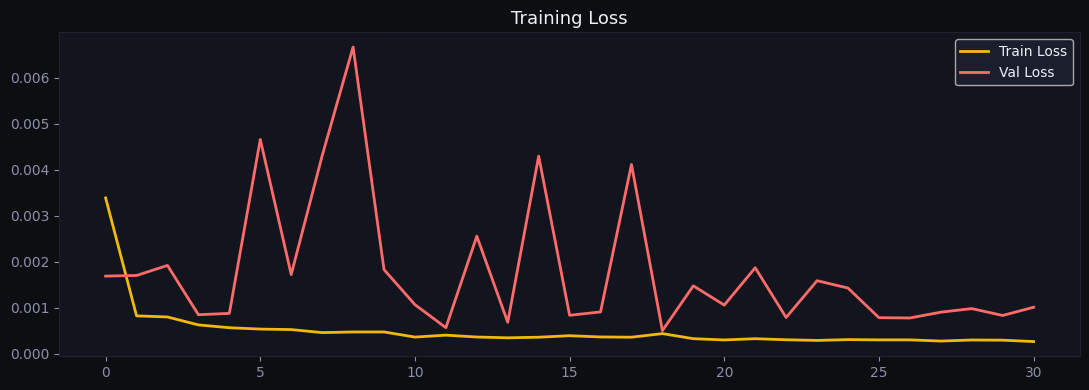

✅ Training complete!


In [6]:
# ══════════════════════════════════════════════════════════
# STEP 6 — Train Model
# ══════════════════════════════════════════════════════════
callbacks = [
    EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-6, verbose=1)
]

history = model.fit(
    X_train, y_train,
    epochs=60, batch_size=32,
    validation_split=0.1,
    callbacks=callbacks, verbose=1
)

# Plot training loss
fig, ax = plt.subplots(figsize=(11, 4))
fig.patch.set_facecolor(DARK); ax.set_facecolor(SURF)
ax.tick_params(colors=MUTED)
for sp in ax.spines.values(): sp.set_color('#1e2130')
ax.plot(history.history['loss'],     color=GOLD, lw=2, label='Train Loss')
ax.plot(history.history['val_loss'], color=RED,  lw=2, label='Val Loss')
ax.set_title('Training Loss', color='#eef0f8', fontsize=13)
ax.legend(facecolor='#1e2130', labelcolor='#eef0f8')
plt.tight_layout()
plt.savefig('training_loss.png', dpi=150, bbox_inches='tight', facecolor=DARK)
plt.show()
print('✅ Training complete!')

══════════════════════════════════════════════════
  MAE       : $    4,586.42
  RMSE      : $    5,537.10
  MAPE      :        4.76%
  R² Score  :        0.9063
  Dir. Acc. :        49.7%
  Accuracy  :       95.24%
══════════════════════════════════════════════════


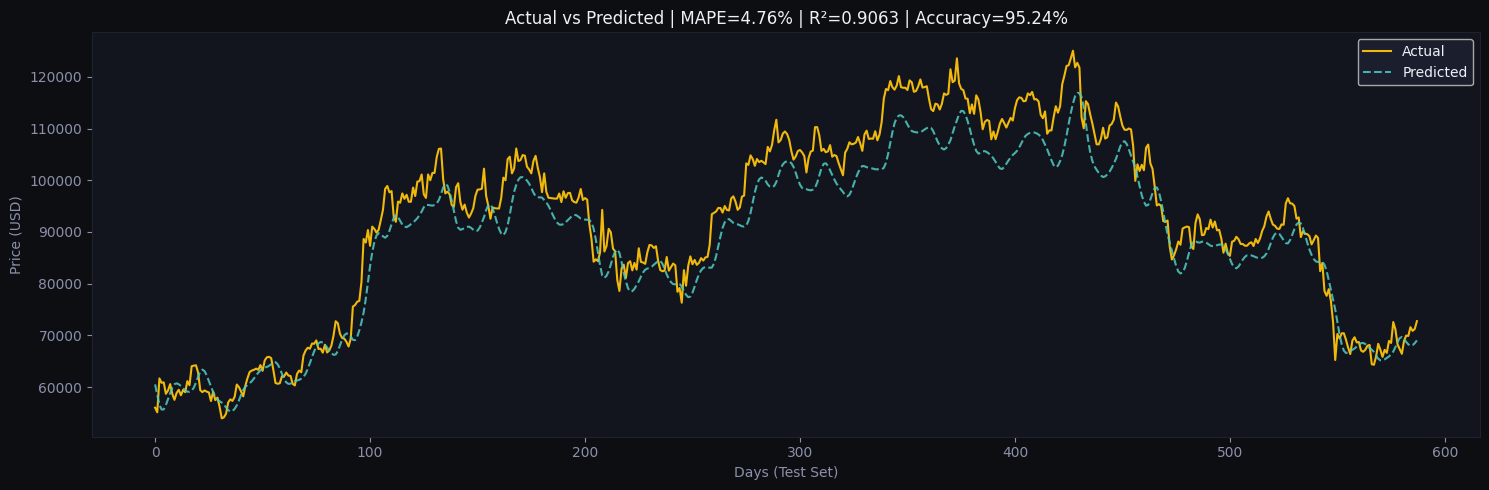

In [7]:
# ══════════════════════════════════════════════════════════
# STEP 7 — Predict & Evaluate
# ══════════════════════════════════════════════════════════
pred_scaled = model.predict(X_test, verbose=0)
pred_prices = scaler.inverse_transform(pred_scaled).flatten()
actual_test = scaler.inverse_transform(y_test.reshape(-1,1)).flatten()

mae  = mean_absolute_error(actual_test, pred_prices)
rmse = np.sqrt(mean_squared_error(actual_test, pred_prices))
mape = np.mean(np.abs((actual_test - pred_prices) / actual_test)) * 100
r2   = 1 - np.sum((actual_test-pred_prices)**2) / np.sum((actual_test-actual_test.mean())**2)
dacc = np.mean(np.sign(np.diff(actual_test)) == np.sign(np.diff(pred_prices))) * 100

print('═'*50)
print(f'  MAE       : ${mae:>12,.2f}')
print(f'  RMSE      : ${rmse:>12,.2f}')
print(f'  MAPE      : {mape:>11.2f}%')
print(f'  R² Score  : {r2:>13.4f}')
print(f'  Dir. Acc. : {dacc:>11.1f}%')
print(f'  Accuracy  : {100-mape:>11.2f}%')
print('═'*50)

# Plot actual vs predicted
fig, ax = plt.subplots(figsize=(15, 5))
fig.patch.set_facecolor(DARK); ax.set_facecolor(SURF)
ax.tick_params(colors=MUTED)
for sp in ax.spines.values(): sp.set_color('#1e2130')
ax.plot(actual_test,  color=GOLD, lw=1.5, label='Actual')
ax.plot(pred_prices,  color=TEAL, lw=1.5, ls='--', label='Predicted', alpha=.85)
ax.set_title(f'Actual vs Predicted | MAPE={mape:.2f}% | R²={r2:.4f} | Accuracy={100-mape:.2f}%',
             color='#eef0f8', fontsize=12)
ax.set_xlabel('Days (Test Set)', color=MUTED)
ax.set_ylabel('Price (USD)', color=MUTED)
ax.legend(facecolor='#1e2130', labelcolor='#eef0f8')
plt.tight_layout()
plt.savefig('btc_prediction.png', dpi=150, bbox_inches='tight', facecolor=DARK)
plt.show()

In [8]:
# ══════════════════════════════════════════════════════════
# STEP 8 — Future Forecast (7, 14, 30 hari ke depan)
# ══════════════════════════════════════════════════════════
from datetime import date, timedelta

def forecast_n_days(model, last_60_scaled, scaler, n):
    seq = last_60_scaled.copy()
    preds = []
    for _ in range(n):
        inp = seq[-60:].reshape(1, 60, 1)
        out = model.predict(inp, verbose=0)[0, 0]
        preds.append(out)
        seq = np.append(seq, [[out]], axis=0)
    return scaler.inverse_transform(np.array(preds).reshape(-1,1)).flatten()

last_seq = scaled[-60:]
today    = date.today()

print(f'Base price (today): ${actual_test[-1]:,.2f}')
for n in [7, 14, 30]:
    fp = forecast_n_days(model, last_seq, scaler, n)
    fd = [(today + timedelta(days=i+1)).strftime('%Y-%m-%d') for i in range(n)]
    ch = (fp[-1] - actual_test[-1]) / actual_test[-1] * 100
    print(f'\n── {n}-Day Forecast (change: {ch:+.1f}%) ──')
    for d, p in zip(fd, fp):
        print(f'  {d}: ${p:>10,.2f}')

Base price (today): $72,750.01

── 7-Day Forecast (change: -4.1%) ──
  2026-06-08: $ 69,754.74
  2026-06-09: $ 70,272.98
  2026-06-10: $ 70,516.61
  2026-06-11: $ 70,518.99
  2026-06-12: $ 70,351.77
  2026-06-13: $ 70,083.62
  2026-06-14: $ 69,764.75

── 14-Day Forecast (change: -7.2%) ──
  2026-06-08: $ 69,754.74
  2026-06-09: $ 70,272.98
  2026-06-10: $ 70,516.61
  2026-06-11: $ 70,518.99
  2026-06-12: $ 70,351.77
  2026-06-13: $ 70,083.62
  2026-06-14: $ 69,764.75
  2026-06-15: $ 69,426.08
  2026-06-16: $ 69,084.16
  2026-06-17: $ 68,746.89
  2026-06-18: $ 68,417.98
  2026-06-19: $ 68,099.45
  2026-06-20: $ 67,792.88
  2026-06-21: $ 67,499.71

── 30-Day Forecast (change: -11.3%) ──
  2026-06-08: $ 69,754.74
  2026-06-09: $ 70,272.98
  2026-06-10: $ 70,516.61
  2026-06-11: $ 70,518.99
  2026-06-12: $ 70,351.77
  2026-06-13: $ 70,083.62
  2026-06-14: $ 69,764.75
  2026-06-15: $ 69,426.08
  2026-06-16: $ 69,084.16
  2026-06-17: $ 68,746.89
  2026-06-18: $ 68,417.98
  2026-06-19: $ 68,0

In [ ]:
# ══════════════════════════════════════════════════════════
# STEP 9 — Simpan Model
# ══════════════════════════════════════════════════════════
model.save('model/bitpredict_lstm_2026.h5')
print("✅ model saved  → model/bitpredict_lstm_2026.h5")

✅ model saved  → model/bitpredict_lstm_2026.h5
